In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the Telco Customer Churn dataset
df = pd.read_csv('../data/WA_Fn-UseC_-Telco-Customer-Churn.csv')

# 2. Display the first 5 rows to make sure it looks correct
df.head()


FileNotFoundError: [Errno 2] No such file or directory: '../data/WA_Fn-UseC_-Telco-Customer-Churn.csv'

In [3]:
import os

# 1. Print where your notebook is currently sitting
print("1. Your notebook is running from:", os.getcwd())

# 2. Check if the 'data' folder exists nearby and look inside it
if os.path.exists('../data'):
    print("\n2. Inside your '../data/' folder, we found these files:")
    print(os.listdir('../data'))
elif os.path.exists('data'):
    print("\n2. Ah! The data folder is right next to your notebook (not one folder back).")
    print("Inside 'data/' folder, we found:")
    print(os.listdir('data'))
else:
    print("\n2. Could not find a 'data' folder using relative paths.")


1. Your notebook is running from: C:\Projects\telco-customer-churn-analysis

2. Inside your '../data/' folder, we found these files:
['processed', 'raw']


In [5]:
df = pd.read_csv('data/WA_Fn-UseC_-Telco-Customer-Churn.csv')


In [6]:
import os

# Check current working directory
print("1. Your notebook is running from:")
print(os.getcwd())

# Look for data files
print("\n2. Checking nearby folders:")
if os.path.exists('data'):
    print("Found 'data' folder directly next to notebook. Files inside:")
    print(os.listdir('data'))
elif os.path.exists('../data'):
    print("Found '../data' folder one directory back. Files inside:")
    print(os.listdir('../data'))
else:
    print("Could not find a 'data' folder using relative paths.")


1. Your notebook is running from:
C:\Projects\telco-customer-churn-analysis

2. Checking nearby folders:
Found 'data' folder directly next to notebook. Files inside:
['WA_Fn-UseC_-Telco-Customer-Churn.csv']


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset directly from the local data folder
df = pd.read_csv('data/WA_Fn-UseC_-Telco-Customer-Churn.csv')

# Display the first 5 rows
df.head()


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [8]:
# 1. Convert TotalCharges to numbers, forcing hidden blank spaces into missing values (NaN)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# 2. Check if any missing values were created from those blank spaces
print("Missing values found in TotalCharges:", df['TotalCharges'].isnull().sum())

# 3. Fill those missing values with 0 (since new customers have 0 charges accumulated)
df['TotalCharges'] = df['TotalCharges'].fillna(0)

# 4. Verify that the column type is now officially a number (float64)
print("New data type for TotalCharges:", df['TotalCharges'].dtype)


Missing values found in TotalCharges: 11
New data type for TotalCharges: float64


--- Churn Percentages ---
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


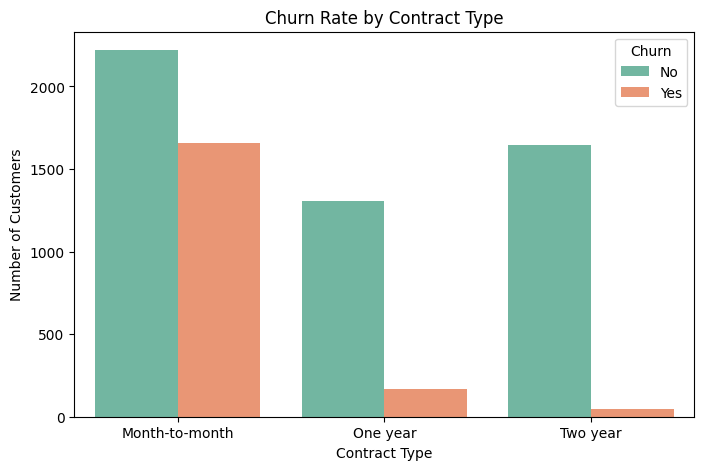

In [9]:
# 1. See the exact percentage breakdown of how many customers left
print("--- Churn Percentages ---")
print(df['Churn'].value_counts(normalize=True) * 100)

# 2. Create a visual bar chart showing Churn rates based on Contract Type
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='Contract', hue='Churn', palette='Set2')
plt.title('Churn Rate by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Number of Customers')
plt.show()


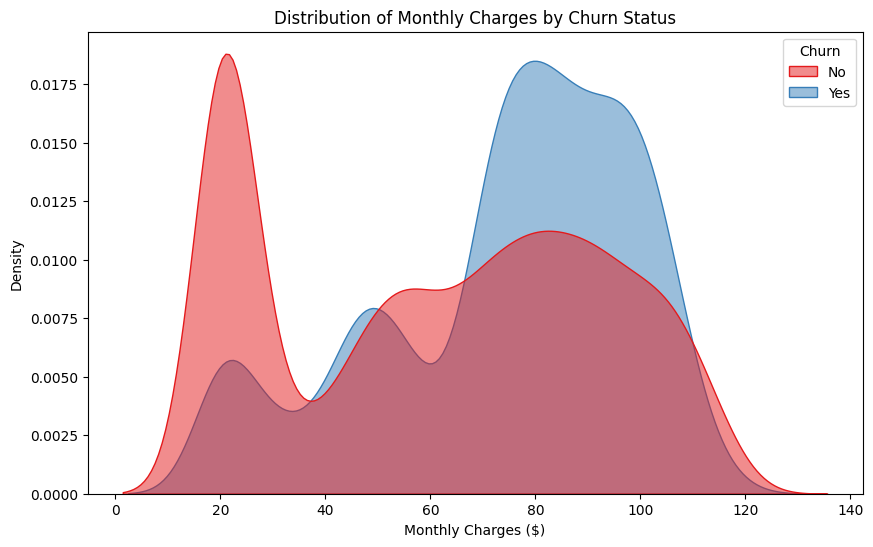

In [10]:
# Create a density plot to see the distribution of Monthly Charges for Churn vs No Churn
plt.figure(figsize=(10, 6))
sns.kdeplot(data=df, x='MonthlyCharges', hue='Churn', fill=True, common_norm=False, palette='Set1', alpha=0.5)

plt.title('Distribution of Monthly Charges by Churn Status')
plt.xlabel('Monthly Charges ($)')
plt.ylabel('Density')
plt.show()


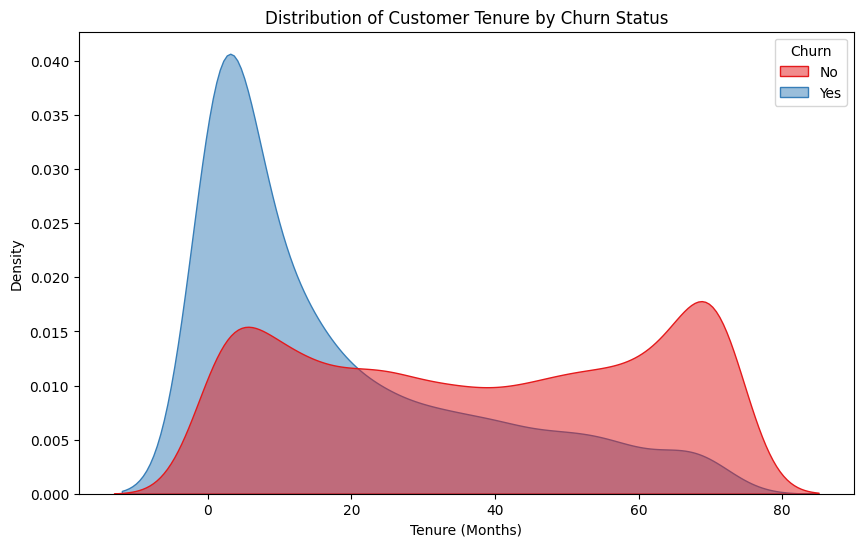

In [11]:
# Create a density plot to see the distribution of tenure (months with company) for Churn vs No Churn
plt.figure(figsize=(10, 6))
sns.kdeplot(data=df, x='tenure', hue='Churn', fill=True, common_norm=False, palette='Set1', alpha=0.5)

plt.title('Distribution of Customer Tenure by Churn Status')
plt.xlabel('Tenure (Months)')
plt.ylabel('Density')
plt.show()


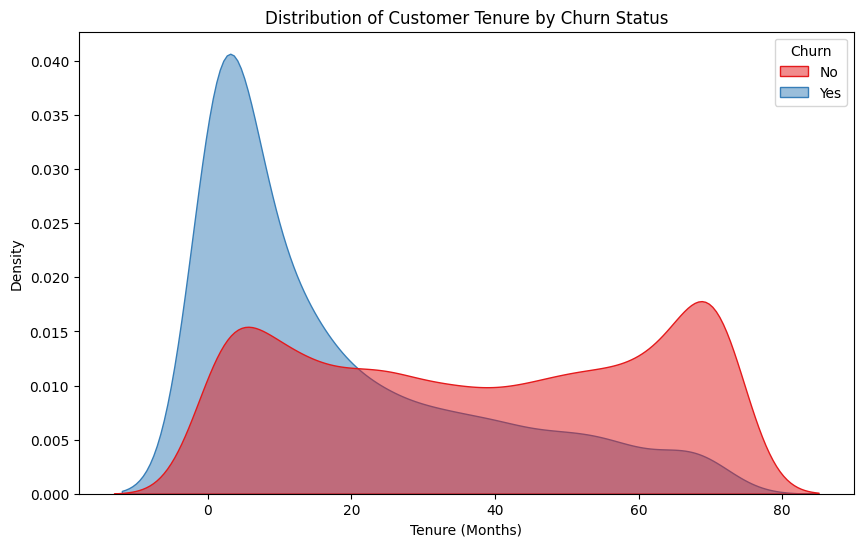

In [12]:
# Create a density plot to see the distribution of tenure (months with company) for Churn vs No Churn
plt.figure(figsize=(10, 6))
sns.kdeplot(data=df, x='tenure', hue='Churn', fill=True, common_norm=False, palette='Set1', alpha=0.5)

plt.title('Distribution of Customer Tenure by Churn Status')
plt.xlabel('Tenure (Months)')
plt.ylabel('Density')
plt.show()


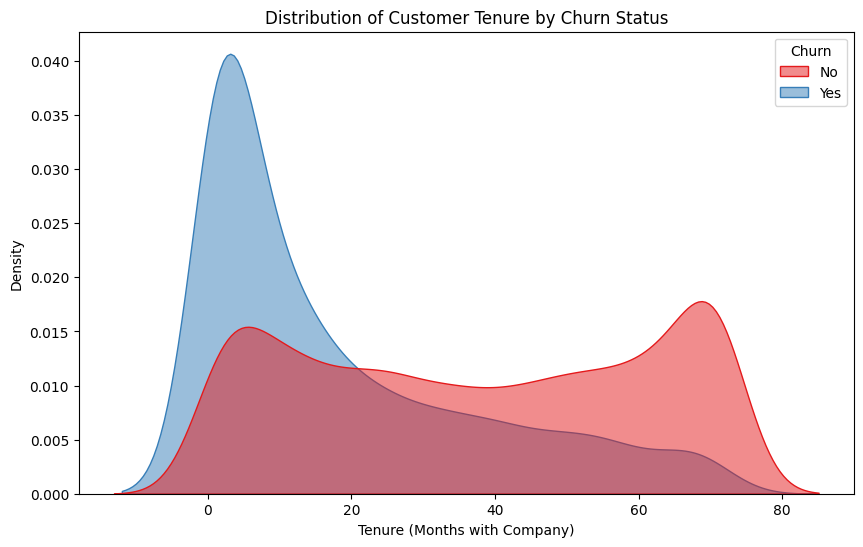

In [13]:
# Create a density plot to see the distribution of tenure for Churn vs No Churn
plt.figure(figsize=(10, 6))
sns.kdeplot(data=df, x='tenure', hue='Churn', fill=True, common_norm=False, palette='Set1', alpha=0.5)

plt.title('Distribution of Customer Tenure by Churn Status')
plt.xlabel('Tenure (Months with Company)')
plt.ylabel('Density')
plt.show()


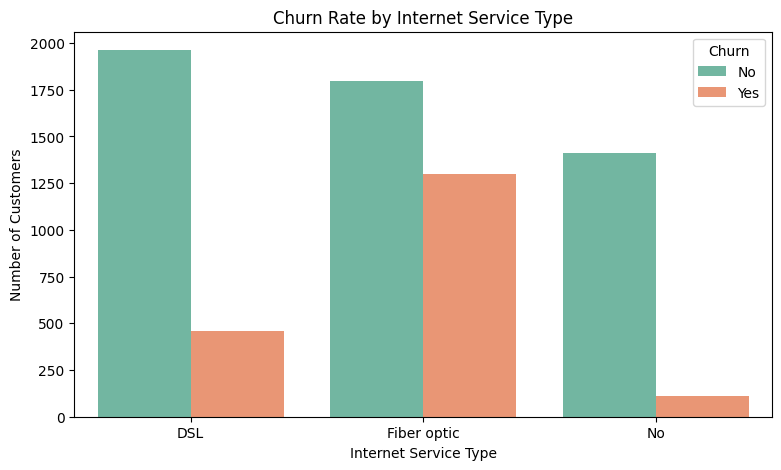

In [14]:
# Create a bar chart showing Churn rates across different Internet Service Types
plt.figure(figsize=(9, 5))
sns.countplot(data=df, x='InternetService', hue='Churn', palette='Set2')

plt.title('Churn Rate by Internet Service Type')
plt.xlabel('Internet Service Type')
plt.ylabel('Number of Customers')
plt.show()


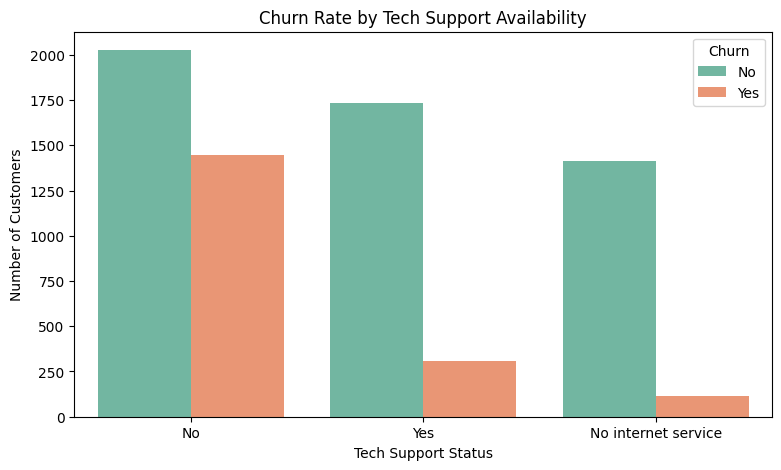

In [15]:
# Create a bar chart showing Churn rates based on Tech Support availability
plt.figure(figsize=(9, 5))
sns.countplot(data=df, x='TechSupport', hue='Churn', palette='Set2')

plt.title('Churn Rate by Tech Support Availability')
plt.xlabel('Tech Support Status')
plt.ylabel('Number of Customers')
plt.show()


In [16]:
# 1. Create a copy of the dataframe for data preparation
prep_df = df.copy()

# 2. Drop the customerID column since it is just an arbitrary identifier
prep_df = prep_df.drop(columns=['customerID'])

# 3. Convert the target column 'Churn' into binary numbers (Yes = 1, No = 0)
prep_df['Churn'] = prep_df['Churn'].map({'Yes': 1, 'No': 0})

# 4. Convert simple two-option text columns into 1s and 0s
binary_cols = ['gender', 'Partner', 'Dependents', 'PhoneService', 'PaperlessBilling']
for col in binary_cols:
    if col == 'gender':
        prep_df['gender'] = prep_df['gender'].map({'Female': 1, 'Male': 0})
    else:
        prep_df[col] = prep_df[col].map({'Yes': 1, 'No': 0})

# 5. Display the first 3 rows of our freshly engineered dataset
prep_df.head(3)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,1,0,1,0,1,0,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,1,Electronic check,29.85,29.85,0
1,0,0,0,0,34,1,No,DSL,Yes,No,Yes,No,No,No,One year,0,Mailed check,56.95,1889.50,0
2,0,0,0,0,2,1,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,1,Mailed check,53.85,108.15,1


In [17]:
# 1. Identify all remaining text columns with multiple options
multi_category_cols = [
    'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 
    'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 
    'Contract', 'PaymentMethod'
]

# 2. Automatically transform these columns into numeric binary columns (One-Hot Encoding)
final_df = pd.get_dummies(prep_df, columns=multi_category_cols, drop_first=True)

# 3. Convert any Boolean True/False columns created into clean 1s and 0s
final_df = final_df.astype(int, errors='ignore')

# 4. View the final matrix shape and a preview of the columns
print("Cleaned Dataset Shape (Rows, Columns):", final_df.shape)
print("\n--- Final Column Samples ---")
print(final_df.columns[:15])


Cleaned Dataset Shape (Rows, Columns): (7043, 31)

--- Final Column Samples ---
Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'PaperlessBilling', 'MonthlyCharges', 'TotalCharges',
       'Churn', 'MultipleLines_No phone service', 'MultipleLines_Yes',
       'InternetService_Fiber optic', 'InternetService_No',
       'OnlineSecurity_No internet service'],
      dtype='object')


In [18]:
from sklearn.model_selection import train_test_split

# 1. Separate your features (X) from the target answer variable (y)
X = final_df.drop(columns=['Churn'])
y = final_df['Churn']

# 2. Split the data into training sets and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 3. Print the sizes of the split datasets to confirm
print("--- Data Split Summary ---")
print(f"Total training customer samples (80%): {X_train.shape[0]}")
print(f"Total testing customer samples  (20%): {X_test.shape[0]}")
print(f"Total features per customer:          {X_train.shape[1]}")


--- Data Split Summary ---
Total training customer samples (80%): 5634
Total testing customer samples  (20%): 1409
Total features per customer:          30


In [19]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Initialize the machine learning model
model = LogisticRegression(max_iter=1000)

# 2. Train the model using your training data
model.fit(X_train, y_train)

# 3. Make churn predictions on the 20% test data the model hasn't seen yet
y_pred = model.predict(X_test)

# 4. Calculate and display the overall accuracy score
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy * 100:.2f}%")

# 5. Display a detailed classification report
print("\n--- Detailed Performance Evaluation ---")
print(classification_report(y_test, y_pred))


Model Accuracy: 80.55%

--- Detailed Performance Evaluation ---
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



C:\Users\Dasari Pallavi\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [20]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# 1. Identify continuous numeric columns that need scaling
numeric_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

# 2. Initialize the StandardScaler
scaler = StandardScaler()

# 3. Create copies of our split datasets to avoid overwriting originals
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

# 4. Fit the scaler on the training features and transform both sets
X_train_scaled[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_test_scaled[numeric_cols] = scaler.transform(X_test[numeric_cols])

# 5. Re-initialize and train the model on the scaled data
scaled_model = LogisticRegression(max_iter=1000)
scaled_model.fit(X_train_scaled, y_train)

# 6. Evaluate the new model's performance
y_pred_scaled = scaled_model.predict(X_test_scaled)
print(f"New Model Accuracy (Scaled): {accuracy_score(y_test, y_pred_scaled) * 100:.2f}%")
print("\n--- New Classification Report ---")
print(classification_report(y_test, y_pred_scaled))


New Model Accuracy (Scaled): 80.70%

--- New Classification Report ---
              precision    recall  f1-score   support

           0       0.85      0.90      0.87      1035
           1       0.66      0.56      0.61       374

    accuracy                           0.81      1409
   macro avg       0.76      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409

